# SCIF3000 — Australian BioResources: NRG Analysis
## Summary
This notebook extends the supplied NSG price comparison into a reusable analytical companion to the feasibility report. It does not establish that an NRG launch is viable. ABR demand, breeding yields, internal costs and substitution behaviour have not been supplied.

Inputs in ASSUMPTIONS are the report's assumptions; ABR should replace them with internal values.

Cell 3 → Table C1，Cell 7 → Table 3，Cell 8 → Table 4，Cell 9 → Table 5，Cell 6 → Figure 3，Cell 10 → Figure 4，Cell 11 → Figure 5，Cell 14 → Figure 1 & 2。

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

def find_data_file(pattern="SCIF3000_Dataset*.xlsx"):
    """Look next to the notebook, then ./data, then one folder up; otherwise ask the user."""
    here = Path.cwd()
    for folder in [here, here / "data", here.parent]:
        hits = sorted(folder.glob(pattern))
        if hits:
            return hits[-1]
    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk(); root.withdraw(); root.attributes("-topmost", True)
        chosen = filedialog.askopenfilename(
            title=f"Select file ({pattern})",
            filetypes=[("Excel files", "*.xlsx *.xlsm *.xls")])
        root.destroy()
        if chosen:
            return Path(chosen)
    except Exception:
        pass
    raise FileNotFoundError(f"Could not find {pattern} in {here}. "
                            "Put the file in the same folder as this notebook and rerun.")

def read_table(path, sheet, first_header):
    """Read a sheet whose header row is the first row starting with `first_header`."""
    raw = pd.read_excel(path, sheet_name=sheet, header=None)
    row = raw.index[raw.iloc[:, 0].astype(str).str.strip() == first_header][0]
    df = pd.read_excel(path, sheet_name=sheet, header=row)
    df.columns = [str(c).strip() for c in df.columns]
    return df

DATA_FILE = find_data_file("SCIF3000_Dataset*.xlsx")
print("Using data file:", DATA_FILE)

OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
AGES = [3, 4, 5, 6, 7, 8]
AGE_COLS = [f"{a} weeks" for a in AGES]

# ABR: replace these with internal values
ASSUMPTIONS = {
    "benchmark_tolerance": 0.50,
    "selling_price_age": 3,
    "founder_price_age": 8,
    "n_founder_mice": 20,
    "import_fee": 184.03, "import_count": 1,
    "shipper_cost": 56.48, "n_shippers": 2,
    "holding_per_cage_week": 20.03, "cages": 15, "weeks_to_first_sale": 12,
    "technician_rate": 100.69, "technician_hours": 20,
    "margins": [0.20, 0.30, 0.40],
    "scale_volumes": [100, 200, 300, 500],
    "max_mice_plot": 500,
}
A = ASSUMPTIONS
tol = A["benchmark_tolerance"]

Using data file: C:\Users\cccxy\Desktop\SCIF3000_Team_O\SCIF3000_Dataset.xlsx


In [2]:
prices = read_table(DATA_FILE, "Prices 1-8 weeks", "Supplier")
prices = prices[prices["Supplier"].notna() & prices["Strain"].notna()].copy()
prices[AGE_COLS] = prices[AGE_COLS].apply(pd.to_numeric, errors="coerce")

def get_prices(supplier, strain):
    row = prices[(prices["Supplier"] == supplier) & (prices["Strain"] == strain)]
    return row[AGE_COLS].iloc[0].astype(float).to_numpy()

oz_nsg = get_prices("Ozgene ARC", "NSG")
oz_nrg = get_prices("Ozgene ARC", "NRG")
abr_nsg = get_prices("ABR (Partners)", "NSG")
prices

,Supplier,Strain,1 week,2 weeks,3 weeks,4 weeks,5 weeks,6 weeks,7 weeks,8 weeks
0,Ozgene ARC,NSG,NaN,NaN,101.62,103.02,104.42,105.82,107.22,108.62
1,Ozgene ARC,NRG,NaN,NaN,238.22,239.62,241.02,242.42,243.82,245.22
2,Ozgene ARC,NOD-SCID,NaN,NaN,161.77,163.17,164.57,165.97,167.37,168.77
3,ABR (Partners),NSG,NaN,NaN,101.22,103.50,104.52,105.65,106.81,108.25
4,ABR (Partners),NRG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,ABR (Partners),NOD-SCID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
def ols(ages, y):
    slope, intercept = np.polyfit(ages, y, 1)
    pred = slope * np.array(ages) + intercept
    r2 = 1 - ((y - pred) ** 2).sum() / ((y - np.mean(y)) ** 2).sum()
    return slope, intercept, r2

fits = {"Ozgene NSG": oz_nsg, "Ozgene NRG": oz_nrg, "ABR NSG (Partners)": abr_nsg}
table_c1 = pd.DataFrame([(k, *ols(AGES, v)) for k, v in fits.items()],
                        columns=["Strain and supplier", "Slope", "Intercept", "R2"]).round(4)
table_c1

,Strain and supplier,Slope,Intercept,R2
0,Ozgene NSG,1.4000,97.4200,1.0000
1,Ozgene NRG,1.4000,234.0200,1.0000
2,ABR NSG (Partners),1.3203,97.7301,0.9831


In [4]:
ratio = oz_nrg / oz_nsg
gap = abr_nsg - oz_nsg
benchmark = pd.DataFrame({"Age (weeks)": AGES, "Ozgene NSG": oz_nsg, "ABR NSG": abr_nsg,
                          "ABR - Ozgene": gap.round(2), "NRG / NSG (Ozgene)": ratio.round(2)})
tol = ASSUMPTIONS["benchmark_tolerance"]
print(f"NRG/NSG ratio range: {ratio.min():.2f} to {ratio.max():.2f}")
print(f"Max |ABR - Ozgene| gap: {np.abs(gap).max():.2f} (within +/-{tol}: {bool((np.abs(gap) <= tol).all())})")
benchmark

NRG/NSG ratio range: 2.26 to 2.34
Max |ABR - Ozgene| gap: 0.48 (within +/-0.5: True)


,Age (weeks),Ozgene NSG,ABR NSG,ABR - Ozgene,NRG / NSG (Ozgene)
0,3,101.62,101.22,-0.40,2.34
1,4,103.02,103.50,0.48,2.33
2,5,104.42,104.52,0.10,2.31
3,6,105.82,105.65,-0.17,2.29
4,7,107.22,106.81,-0.41,2.27
5,8,108.62,108.25,-0.37,2.26


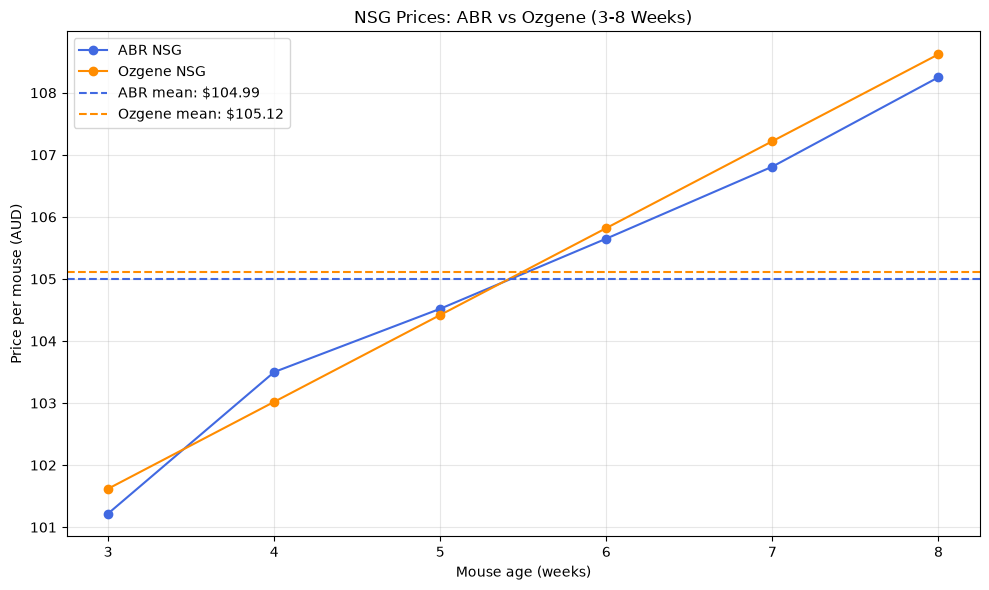

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(AGES, abr_nsg, marker="o", color="royalblue", label="ABR NSG")
ax.plot(AGES, oz_nsg, marker="o", color="darkorange", label="Ozgene NSG")
ax.axhline(abr_nsg.mean(), color="royalblue", ls="--", label=f"ABR mean: ${abr_nsg.mean():.2f}")
ax.axhline(oz_nsg.mean(), color="darkorange", ls="--", label=f"Ozgene mean: ${oz_nsg.mean():.2f}")
ax.set(xlabel="Mouse age (weeks)", ylabel="Price per mouse (AUD)",
       title="NSG Prices: ABR vs Ozgene (3-8 Weeks)", xticks=AGES)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_nsg_abr_vs_ozgene.png", dpi=300)
plt.show()

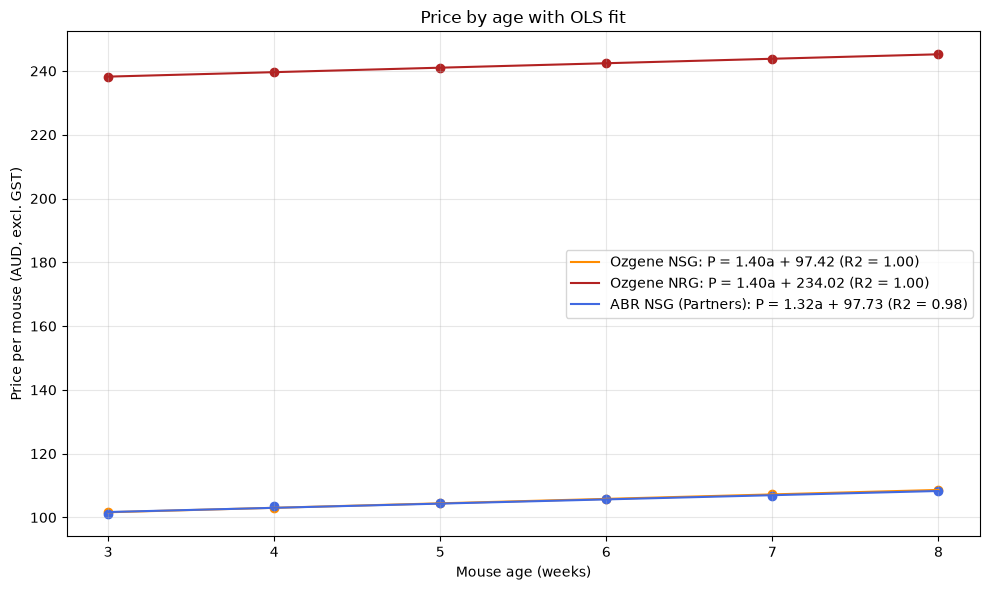

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
x = np.linspace(3, 8, 100)
for (name, y), c in zip(fits.items(), ["darkorange", "firebrick", "royalblue"]):
    s, i, r2 = ols(AGES, y)
    ax.scatter(AGES, y, color=c)
    ax.plot(x, s * x + i, color=c, label=f"{name}: P = {s:.2f}a + {i:.2f} (R2 = {r2:.2f})")
ax.set(xlabel="Mouse age (weeks)", ylabel="Price per mouse (AUD, excl. GST)",
       title="Price by age with OLS fit", xticks=AGES)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig3_price_regression.png", dpi=300)
plt.show()

In [7]:
s_nrg, i_nrg, _ = ols(AGES, oz_nrg)
table3 = pd.DataFrame({"Age (weeks)": AGES,
                       "Estimated ABR NRG price": (s_nrg * np.array(AGES) + i_nrg).round(2)})
table3["Lower (-tol)"] = (table3["Estimated ABR NRG price"] - tol).round(2)
table3["Upper (+tol)"] = (table3["Estimated ABR NRG price"] + tol).round(2)
table3

,Age (weeks),Estimated ABR NRG price,Lower (-tol),Upper (+tol)
0,3,238.22,237.72,238.72
1,4,239.62,239.12,240.12
2,5,241.02,240.52,241.52
3,6,242.42,241.92,242.92
4,7,243.82,243.32,244.32
5,8,245.22,244.72,245.72


In [8]:
A = ASSUMPTIONS
founder_price = oz_nrg[AGES.index(A["founder_price_age"])]
items = [
    ("Founder NRG mice", founder_price, A["n_founder_mice"], "No. mice"),
    ("National import fee", A["import_fee"], A["import_count"], "No. imports"),
    ("Shipping", A["shipper_cost"], A["n_shippers"], "No. shippers"),
    ("Husbandry", A["holding_per_cage_week"], A["cages"] * A["weeks_to_first_sale"], "Cage/week"),
    ("Technician", A["technician_rate"], A["technician_hours"], "Hours"),
]
table4 = pd.DataFrame(items, columns=["Item", "Unit cost", "Quantity", "Unit"])
table4["Cost"] = (table4["Unit cost"] * table4["Quantity"]).round(2)
F = table4["Cost"].sum()
print(f"One-time set-up cost F = ${F:,.0f}")
table4

One-time set-up cost F = $10,821


,Item,Unit cost,Quantity,Unit,Cost
0,Founder NRG mice,245.22,20,No. mice,4904.40
1,National import fee,184.03,1,No. imports,184.03
2,Shipping,56.48,2,No. shippers,112.96
3,Husbandry,20.03,180,Cage/week,3605.40
4,Technician,100.69,20,Hours,2013.80


In [9]:
price = oz_nrg[AGES.index(A["selling_price_age"])]
rows = []
for m in A["margins"]:
    profit = m * price
    rows.append((f"{int(m*100)}% margin", m, round(profit, 2), round(F), int(np.ceil(F / profit))))
table5 = pd.DataFrame(rows, columns=["Scenario", "Margin", "Profit per mouse",
                                     "Set-up cost", "Mice to break even"])
print(f"Assumed selling price p = ${price:.2f}")
table5

Assumed selling price p = $238.22


,Scenario,Margin,Profit per mouse,Set-up cost,Mice to break even
0,20% margin,0.2,47.64,10821,228
1,30% margin,0.3,71.47,10821,152
2,40% margin,0.4,95.29,10821,114


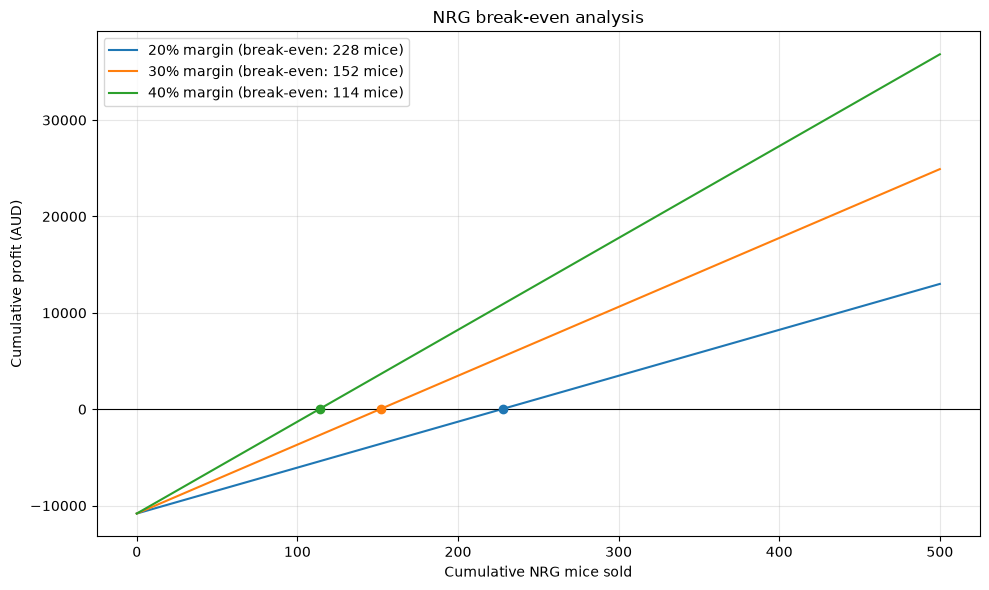

In [10]:
n = np.arange(0, A["max_mice_plot"] + 1)
fig, ax = plt.subplots(figsize=(10, 6))
for m, nbe in zip(A["margins"], table5["Mice to break even"]):
    ax.plot(n, n * m * price - F, label=f"{int(m*100)}% margin (break-even: {nbe} mice)")
    ax.scatter([nbe], [0], zorder=3)
ax.axhline(0, color="black", lw=0.8)
ax.set(xlabel="Cumulative NRG mice sold", ylabel="Cumulative profit (AUD)",
       title="NRG break-even analysis")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig4_break_even.png", dpi=300)
plt.show()

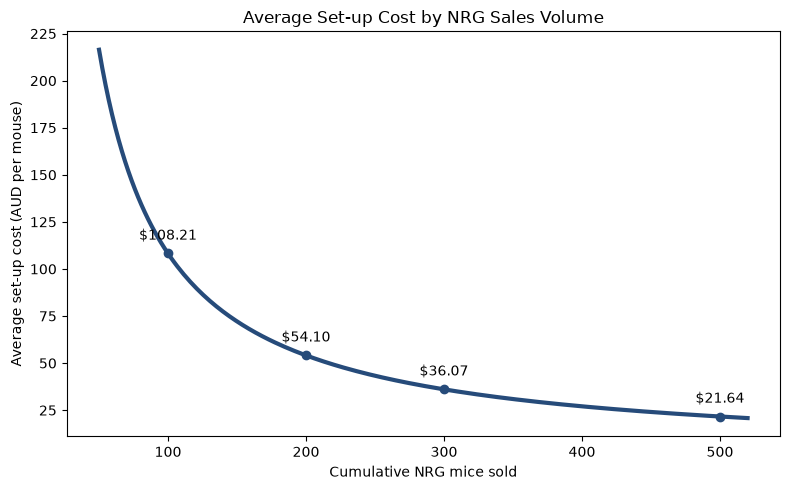

,Mice sold,Avg set-up cost per mouse
0,100,108.21
1,200,54.10
2,300,36.07
3,500,21.64


In [11]:
vols = A["scale_volumes"]
afc = pd.DataFrame({"Mice sold": vols, "Avg set-up cost per mouse": [round(F / v, 2) for v in vols]})
fig, ax = plt.subplots(figsize=(8, 5))
xs = np.linspace(50, A["max_mice_plot"] + 20, 200)
ax.plot(xs, F / xs, color="#264b7a", lw=3)
ax.scatter(afc["Mice sold"], afc["Avg set-up cost per mouse"], color="#264b7a", zorder=3)
for v, c in zip(afc["Mice sold"], afc["Avg set-up cost per mouse"]):
    ax.annotate(f"${c:.2f}", (v, c), textcoords="offset points", xytext=(0, 10), ha="center")
ax.set(xlabel="Cumulative NRG mice sold", ylabel="Average set-up cost (AUD per mouse)",
       title="Average Set-up Cost by NRG Sales Volume")
fig.tight_layout()
fig.savefig(OUT_DIR / "fig5_avg_setup_cost.png", dpi=300)
plt.show()
afc

In [12]:
MRFF_FILE = find_data_file("medical-research-future-fund-mrff-grant-recipients*.xlsx")
print("Using MRFF file:", MRFF_FILE)

mrff_raw = pd.read_excel(MRFF_FILE, sheet_name="Grants List").iloc[:, :17]
mrff_raw.columns = [re.sub(r"\s+", " ", str(c)).strip() for c in mrff_raw.columns]
mrff_raw["start"] = pd.to_datetime(mrff_raw["Contract Start Date"], errors="coerce")
mrff_raw["value"] = pd.to_numeric(mrff_raw["Total Grant Value"], errors="coerce")
mrff_raw = mrff_raw.dropna(subset=["start", "value"])

CANCER_KEYWORDS = (r"cancer|oncolog|tumou?r|leuka?emia|lymphoma|melanoma|carcinoma|neoplas|"
                   r"malignan|metasta|glioma|glioblastoma|myeloma|sarcoma|neuroblastoma")
SEARCH_COLS = ["MRFF Initiative", "Grant Opportunity", "Project Name", "Project Summary",
               "Broad Research Area", "Field(s) of Research (DIVISION / Group / Field)"]
MRFF_YEARS = range(2017, 2026)

text = mrff_raw[SEARCH_COLS].fillna("").astype(str).agg(" ".join, axis=1).str.lower()
mrff_cancer = mrff_raw[text.str.contains(CANCER_KEYWORDS, regex=True)].copy()
mrff_cancer["year"] = mrff_cancer["start"].dt.year

mrff_table = (mrff_cancer[mrff_cancer["year"].isin(MRFF_YEARS)]
              .groupby("year")["value"].agg(["count", "sum"]))
mrff_table["AUD million"] = (mrff_table["sum"] / 1e6).round(1)
mrff_table = mrff_table.rename(columns={"count": "No. grants"})[["No. grants", "AUD million"]]
mrff = mrff_table["AUD million"]
print(f"{len(mrff_cancer)} cancer-related grants identified from {len(mrff_raw)} MRFF grants")
mrff_table

Using MRFF file: C:\Users\cccxy\Desktop\SCIF3000_Team_O\medical-research-future-fund-mrff-grant-recipients_0.xlsx
410 cancer-related grants identified from 1915 MRFF grants


,No. grants,AUD million
year,,
2017,2,7.2
2018,21,55.3
2019,50,76.0
2020,67,188.2
2021,64,126.5
2022,48,136.6
2023,49,141.7
2024,40,89.5
2025,44,146.2


In [13]:
AREA = "Cancer"     # ABR can change this to another NHMRC area
try:
    nh = pd.read_excel(DATA_FILE, sheet_name="NHMRC disease areas")
    nh = nh.set_index(nh.columns[0])
    nh.index = nh.index.astype(str).str.strip()
    nh.columns = [int(c) for c in nh.columns]
    nhmrc = nh.loc[AREA].astype(float)
except ValueError:
    print("Sheet 'NHMRC disease areas' not found, using the report values")
    nhmrc = pd.Series({2016: 170.6, 2017: 175.8, 2018: 178.9, 2019: 181.6, 2020: 170.2,
                       2021: 153.7, 2022: 158.9, 2023: 165.6, 2024: 164.7, 2025: 186.0})
TREND_START = 2021
tr = nhmrc[nhmrc.index >= TREND_START]
slope, intercept = np.polyfit(tr.index, tr.values, 1)
print(f"NHMRC {AREA} linear trend {TREND_START}-{nhmrc.index.max()}: +{slope:.2f} AUD million per year")
nhmrc.to_frame("AUD million")

Sheet 'NHMRC disease areas' not found, using the report values
NHMRC Cancer linear trend 2021-2025: +7.04 AUD million per year


,AUD million
2016,170.6
2017,175.8
2018,178.9
2019,181.6
2020,170.2
2021,153.7
2022,158.9
2023,165.6
2024,164.7
2025,186.0


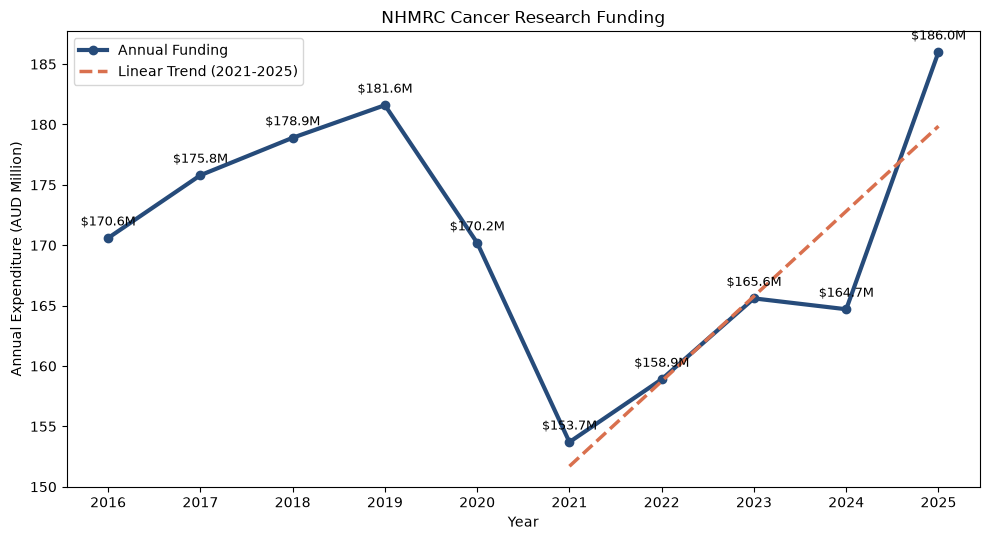

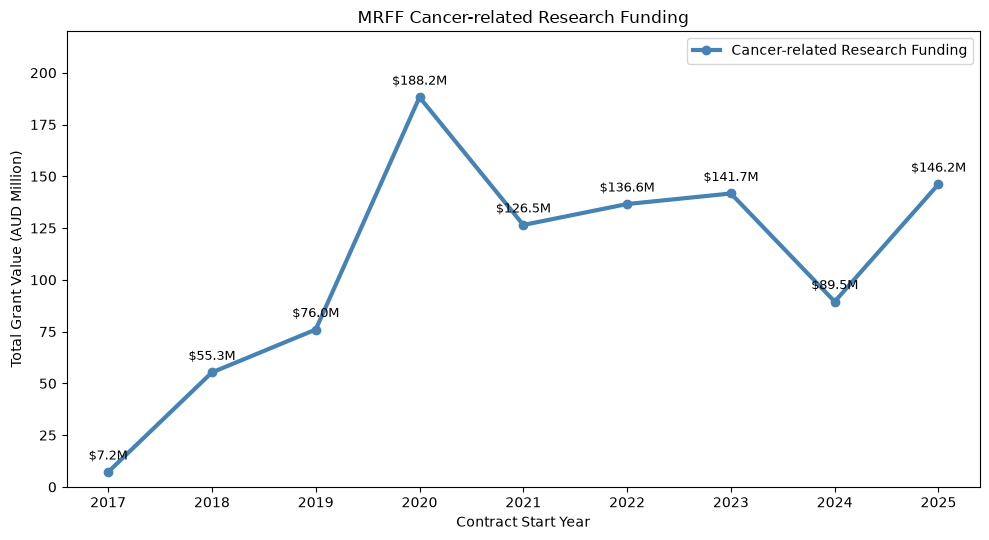

In [14]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(nhmrc.index, nhmrc.values, marker="o", color="#264b7a", lw=3, label="Annual Funding")
ax.plot(tr.index, slope * tr.index + intercept, "--", color="#d9704e", lw=2.5,
        label=f"Linear Trend ({TREND_START}-{nhmrc.index.max()})")
for yv, v in nhmrc.items():
    ax.annotate(f"${v:.1f}M", (yv, v), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.set(xlabel="Year", ylabel="Annual Expenditure (AUD Million)",
       title=f"NHMRC {AREA} Research Funding", xticks=list(nhmrc.index))
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "fig1_nhmrc.png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(mrff.index, mrff.values, marker="o", color="steelblue", lw=3, label="Cancer-related Research Funding")
for yv, v in mrff.items():
    ax.annotate(f"${v:.1f}M", (yv, v), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.set(xlabel="Contract Start Year", ylabel="Total Grant Value (AUD Million)",
       title="MRFF Cancer-related Research Funding", xticks=list(mrff.index), ylim=(0, 220))
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "fig2_mrff.png", dpi=300)
plt.show()

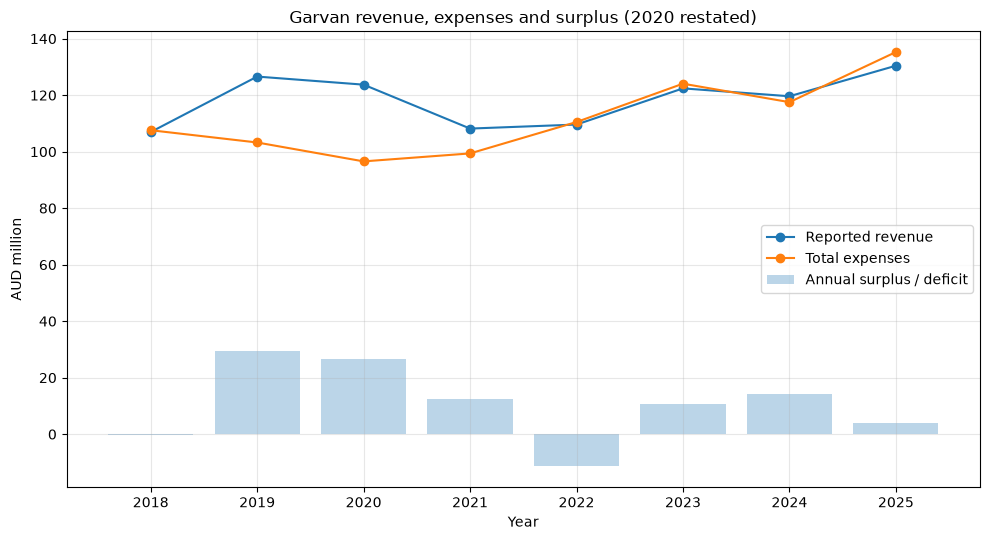

Set-up cost = 0.26% of Garvan 2025 surplus


In [15]:
g = read_table(DATA_FILE, "Summary", "Financial metric").dropna(subset=["Financial metric"])
g = g.set_index("Financial metric").apply(pd.to_numeric, errors="coerce")
g.columns = [int(c) for c in g.columns]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(g.columns, g.loc["Reported revenue"], marker="o", label="Reported revenue")
ax.plot(g.columns, g.loc["Total expenses"], marker="o", label="Total expenses")
ax.bar(g.columns, g.loc["Annual surplus / deficit"], alpha=0.3, label="Annual surplus / deficit")
ax.set(xlabel="Year", ylabel="AUD million",
       title="Garvan revenue, expenses and surplus (2020 restated)", xticks=list(g.columns))
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_garvan.png", dpi=300)
plt.show()

share = F / (g.loc["Annual surplus / deficit", 2025] * 1e6) * 100
print(f"Set-up cost = {share:.2f}% of Garvan 2025 surplus")

In [16]:
with pd.ExcelWriter(OUT_DIR / "ABR_NRG_analysis_tables.xlsx") as w:
    for name, df in {"C1_price_fit": table_c1, "Benchmark": benchmark, "T3_NRG_price": table3,
                     "T4_setup": table4, "T5_breakeven": table5, "Avg_setup": afc,
                     "MRFF_cancer_by_year": mrff_table.reset_index(),
                     "NHMRC": nhmrc.rename("AUD million").reset_index()}.items():
        df.to_excel(w, sheet_name=name, index=False)
print("Saved to", OUT_DIR.resolve())

Saved to C:\Users\cccxy\Desktop\SCIF3000_Team_O\outputs
